# Análise do Dataset IRIS

Nesse notebook iremos analisar o dataset IRIS, que contém 50 instâncias de 3 tipos de plantas diferentes: Setosa, Versicolour, ou Virginica. As *features* são o comprimento e largura das pétalas e sépalas de cada planta.

In [1]:
from src.dataset import IRISDataset
from src.charts import plot_distributions, plot_scatter_matrix
from src.pca import pca_decomposition
from src.classification import split_data, evaluate_knn, train_knn
from sklearn.neighbors import KNeighborsClassifier

dataset = IRISDataset()
df = dataset.X

## Análise Estatística

Começamos analisando a média, desvio padrão e moda geral e por categoria, além da frequência de cada categoria. Mostramos a tabela das estatísticas e também a distribuição das variáveis em um histograma separado por classes e por variável

In [2]:
df['target'] = dataset.y

def get_mode(x):
    # corrigido: antes devolvia x.iloc[0] (o primeiro valor do grupo), não a moda.
    # Quando há empate, mostra todas as modas.
    mode = x.mode()
    return '/'.join(f'{v:g}' for v in mode) if not mode.empty else None

aggregation = df.groupby('target').agg({
    'sepal length' : ["mean", "std", "count", get_mode],
    'sepal width' : ["mean", "std", "count", get_mode],
    'petal length' : ["mean", "std", "count", get_mode],
    'petal width' : ["mean", "std", "count", get_mode],
    })
aggregation

sepal length                              sepal width  \
                        mean       std count     get_mode        mean   
target                                                                  
Iris-setosa            5.006  0.352490    50        5/5.1       3.418   
Iris-versicolor        5.936  0.516171    50  5.5/5.6/5.7       2.770   
Iris-virginica         6.588  0.635880    50          6.3       2.974   

                                         petal length                  \
                      std count get_mode         mean       std count   
target                                                                  
Iris-setosa      0.381024    50      3.4        1.464  0.173511    50   
Iris-versicolor  0.313798    50        3        4.260  0.469911    50   
Iris-virginica   0.322497    50        3        5.552  0.551895    50   

                         petal width                           
                get_mode        mean       std count get_mode  
target                                                         
Iris-setosa          1.5       0.244  0.107210    50      0.2  
Iris-versicolor      4.5       1.326  0.197753    50      1.3  
Iris-virginica       5.1       2.026  0.274650    50      1.8

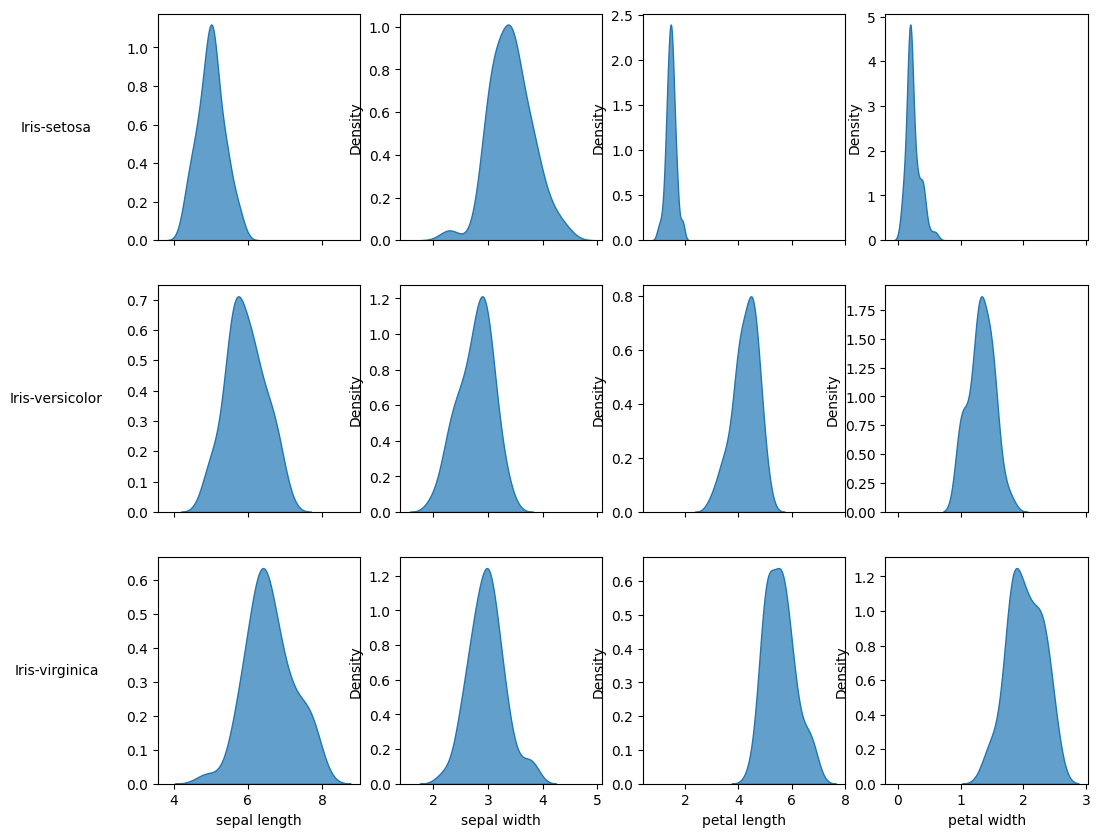

In [3]:
plot_distributions(df, 'target')

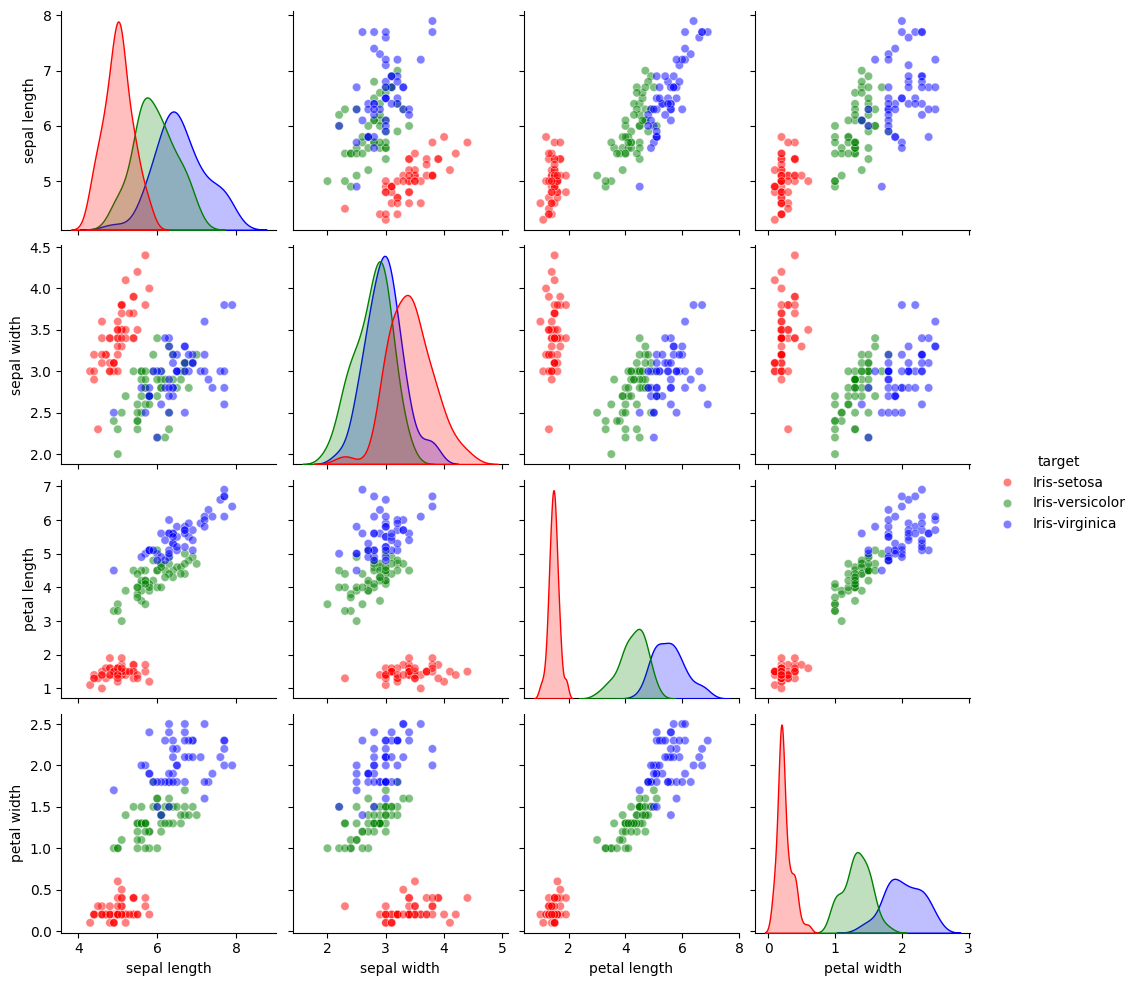

In [4]:
plot_scatter_matrix(df, 'target')

### Resultados

Podemos ver que a Virginica tem, em média, sépalas mais compridas e com maior variância (6.6 ± 0.6) em comparação com os outros tipos, enquanto a Setosa tem uma sépala mais larga que todas as outras. O comprimento da pétala também muda bastante, com a Virginica tendo a pétala mais comprida e mais larga em média (5.6 ± 0.6 e 2.0 ± 0.3) quando comparada com as outras.

Pelos gráficos, podemos ver que a Setosa possui as pétalas menores, sépalas menos compridas e mais largas. Já a Virginica e Versicolor são mais parecidas, sendo a Versicolor um pouco menor em todas as váriaveis do que a Virginica. No *scatter plot* podemos ver que a Setosa (em vermelho) possui uma separação maior do que as outras duas plantas, que possuem pontos mais próximos na maioria dos gráficos.

## PCA

Nesta seção, utilizamos o método de *Principal Component Analysis* para reduzir as 4 *features* do dataset para podermos criar gráficos que mostrem a separação possível das classes. Reduzimos de 4 *features* para 3 e posteriormente para 2, e analisamos os gráficos resultantes.

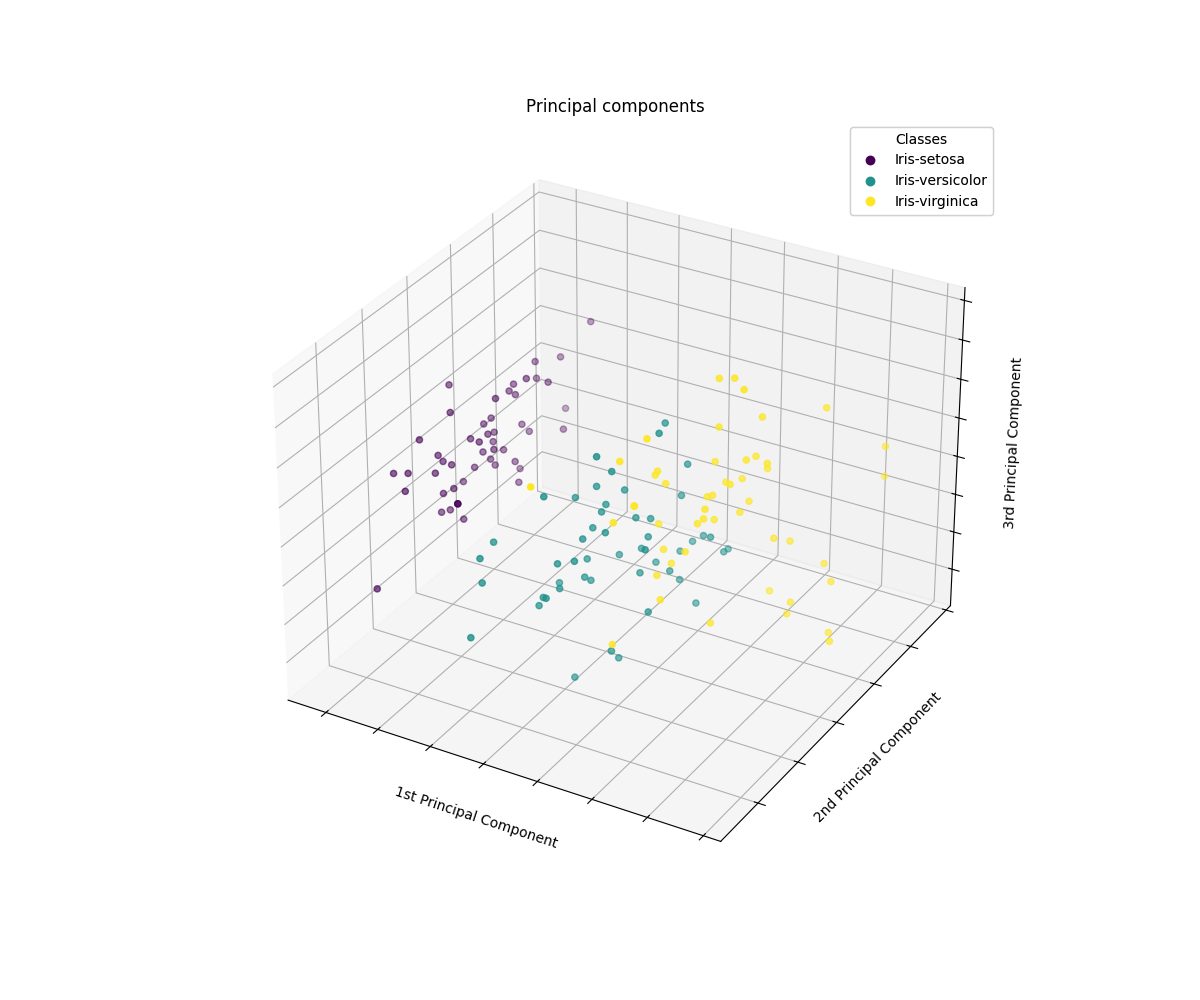

In [5]:
%matplotlib widget

pca_decomposition(df, 'target')

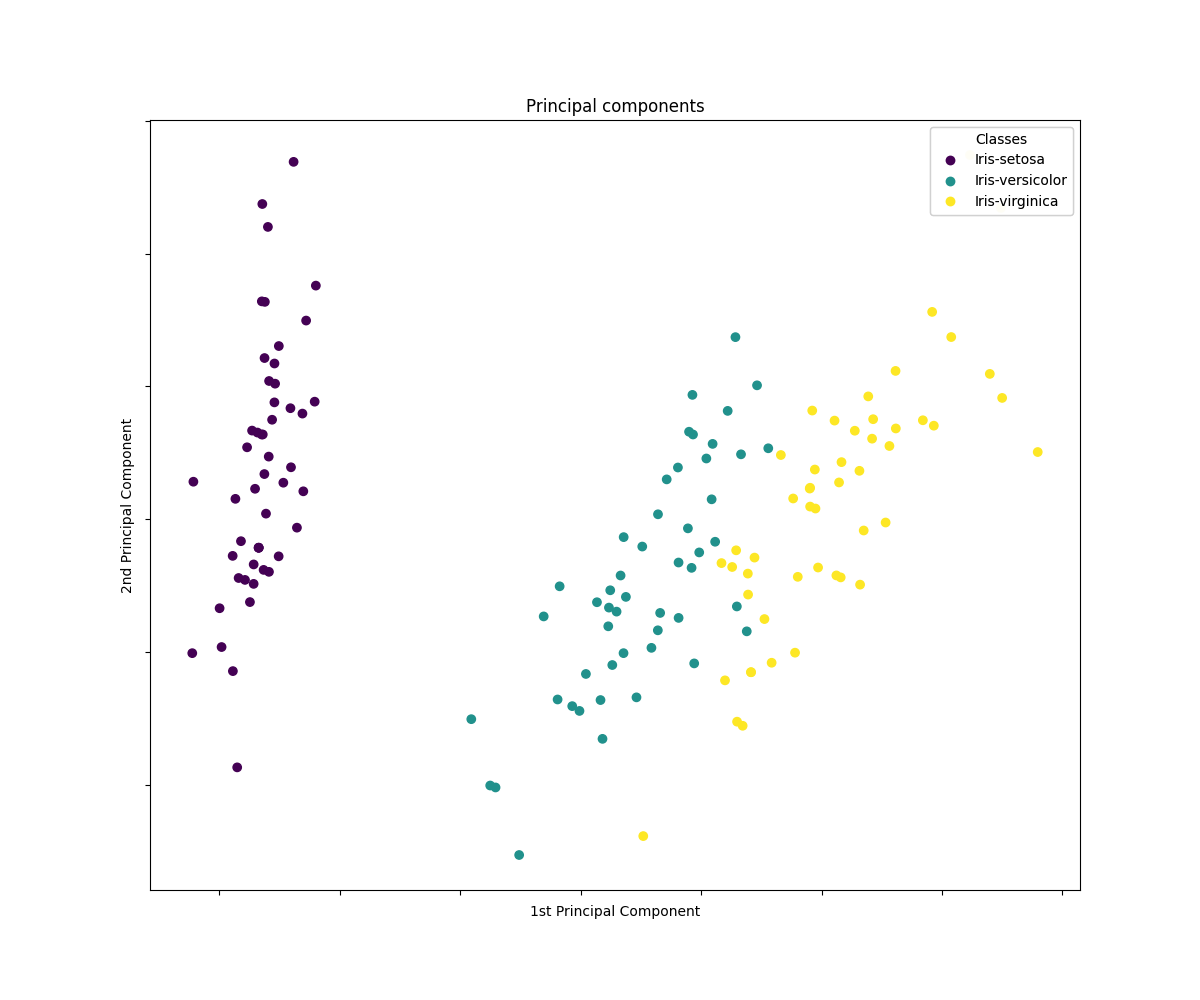

In [6]:
pca_decomposition(df, 'target', n_components=2)

Podemos ver que o método do PCA consegue transformar as *features* em dimensões menores que separam quase linearmente as classes, tanto na versão de 3 *features* quanto com apenas 2.

## Classificação KNN

### Separação dos Dados

Para treinar um KNN, separamos os dados em 80% para treinamento e 20% para teste. Avaliamos o resultado com as métricas de acurácia, precisão e sensibilidade.

In [49]:
train_set, test_set = split_data(df, 'target', test_size=0.2)
print(f"""
Tamanho do Dataset de treinamento: {len(train_set.X)}
Tamanho do Dataset de teste: {len(test_set.X)}
""")


Tamanho do Dataset de treinamento: 120
Tamanho do Dataset de teste: 30



### Treinamento

Para treinarmos o KNN, primeiro normalizamos os dados para evitar que *features* de maior magnitude dominem o resultado final. Normalizamos os dados para que todas as *features* tenham média 0 e variância 1.

In [47]:
knn = train_knn(train_set, n_neighbors=3)
knn

,steps,"[('scaler', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


### Resultado

Avaliamos o KNN treinado em 3 métricas distintas: acurácia, precisão e sensibilidade.

In [48]:
acc, prc, rec = evaluate_knn(knn, test_set)

print(f"""Accuracy: {acc:0.2f}
Precision: {prc:0.2f}
Recall: {rec:0.2f}""")

Accuracy: 0.93
Precision: 0.93
Recall: 0.93


---
# Análise complementar

As seções abaixo completam a análise com o que o relatório apontava como limitações: variância explicada do PCA, variabilidade entre divisões, divisão estratificada com matriz de confusão e métricas por classe, escolha de *k* por validação cruzada, KNN com e sem PCA, análise dos erros e fronteiras de decisão.

**Sobre as saídas acima:** a divisão treino/teste da seção *Classificação KNN* não tem semente, então cada execução gera outro resultado. As saídas acima são as da execução registrada no relatório (acurácia de 0,93). Todas as análises a seguir usam sementes fixas e são reprodutíveis. As funções novas estão em `src/` e as figuras do relatório são salvas em `figuras/`.

In [50]:
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from src.dataset import FEATURES
from src.pca import pca_summary
from src.classification import (split_data, train_knn, evaluate_per_class, split_variability, select_k,
                                train_knn_pipeline, compare_configs, cross_validation_errors)
from src.charts import (set_report_style, save_figure, plot_feature_densities, plot_sepal_petal, plot_pca_projections,
                        plot_split_variability, plot_k_selection, plot_confusion_and_errors, plot_decision_boundaries, CLASS_NAMES)

set_report_style()
R = {'fonte': dataset.source}                       # números do relatório (salvos em resultados.json)
X = df[FEATURES]
y = pd.Categorical(df['target'], categories=sorted(df['target'].unique())).codes   # 0 setosa, 1 versicolor, 2 virginica
print("fonte dos dados:", dataset.source, "| amostras por classe:", np.bincount(y))

fonte dos dados: scikit-learn + correções UCI | amostras por classe: [50 50 50]


## Estatísticas descritivas (complemento)

A tabela da seção *Análise Estatística* agora mostra a moda correta. A versão anterior de `get_mode` devolvia `x.iloc[0]`, o primeiro valor de cada grupo. Abaixo, a comparação entre os dois valores, seguida de mínimo, máximo e correlações.

In [51]:
comparacao = pd.DataFrame([{'espécie': esp, 'atributo': f, 'valor antigo (1º valor)': g[f].iloc[0],
                            'moda correta': get_mode(g[f]), 'frequência da moda': int(g[f].value_counts().max())}
                           for esp, g in df.groupby('target') for f in FEATURES])
print("células em que o valor antigo não era (uma das) moda(s):",
      sum(f'{a:g}' not in m.split('/') for a, m in zip(comparacao['valor antigo (1º valor)'], comparacao['moda correta'])), "de", len(comparacao))
display(comparacao)
display(df.groupby('target')[FEATURES].agg(['mean', 'std', 'min', 'max']).round(3))
corr = X.corr(); display(corr.round(3))
R['estatisticas'] = {esp: {f: {'media': round(g[f].mean(), 3), 'dp': round(g[f].std(), 3), 'moda': get_mode(g[f])} for f in FEATURES}
                     for esp, g in df.groupby('target')}
R['corr_petalas'] = round(corr.loc['petal length', 'petal width'], 3)
R['corr_sepala_petala'] = round(corr.loc['sepal length', 'petal length'], 3)
R['corr_largsepala_comppetala'] = round(corr.loc['sepal width', 'petal length'], 3)

células em que o valor antigo não era (uma das) moda(s): 9 de 12


,espécie,atributo,valor antigo (1º valor),moda correta,frequência da moda
0,Iris-setosa,sepal length,5.1,5/5.1,8
1,Iris-setosa,sepal width,3.5,3.4,9
2,Iris-setosa,petal length,1.4,1.5,14
3,Iris-setosa,petal width,0.2,0.2,28
4,Iris-versicolor,sepal length,7.0,5.5/5.6/5.7,5
5,Iris-versicolor,sepal width,3.2,3,8
6,Iris-versicolor,petal length,4.7,4.5,7
7,Iris-versicolor,petal width,1.4,1.3,13
8,Iris-virginica,sepal length,6.3,6.3,6
9,Iris-virginica,sepal width,3.3,3,12


sepal length                  sepal width                   \
                        mean    std  min  max        mean    std  min  max   
target                                                                       
Iris-setosa            5.006  0.352  4.3  5.8       3.418  0.381  2.3  4.4   
Iris-versicolor        5.936  0.516  4.9  7.0       2.770  0.314  2.0  3.4   
Iris-virginica         6.588  0.636  4.9  7.9       2.974  0.322  2.2  3.8   

                petal length                  petal width                   
                        mean    std  min  max        mean    std  min  max  
target                                                                      
Iris-setosa            1.464  0.174  1.0  1.9       0.244  0.107  0.1  0.6  
Iris-versicolor        4.260  0.470  3.0  5.1       1.326  0.198  1.0  1.8  
Iris-virginica         5.552  0.552  4.5  6.9       2.026  0.275  1.4  2.5

,sepal length,sepal width,petal length,petal width
sepal length,1.000,-0.109,0.872,0.818
sepal width,-0.109,1.000,-0.421,-0.357
petal length,0.872,-0.421,1.000,0.963
petal width,0.818,-0.357,0.963,1.000


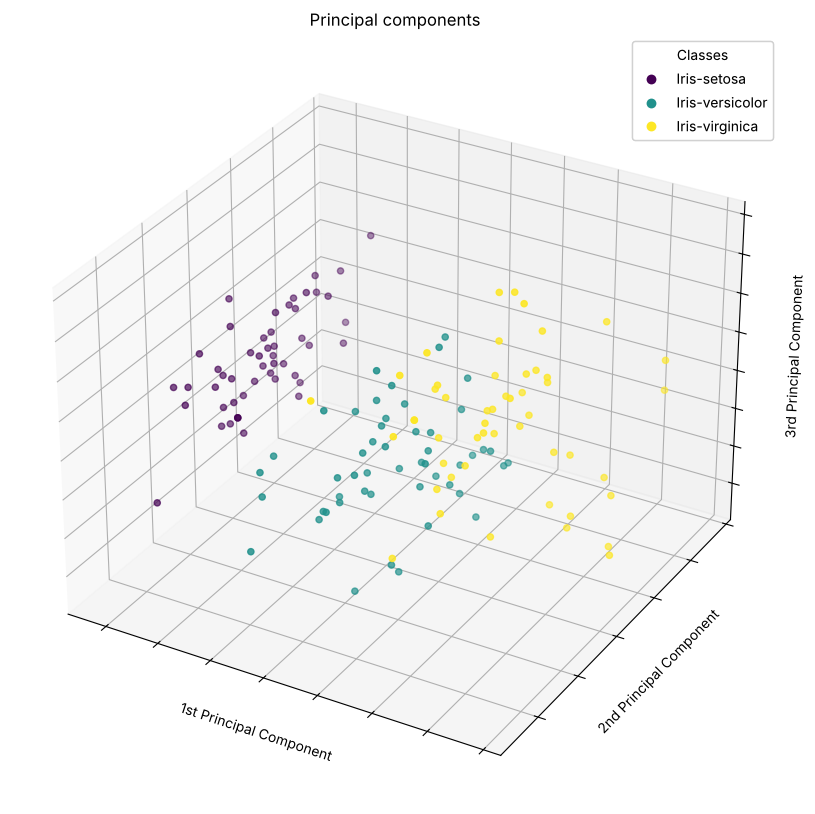

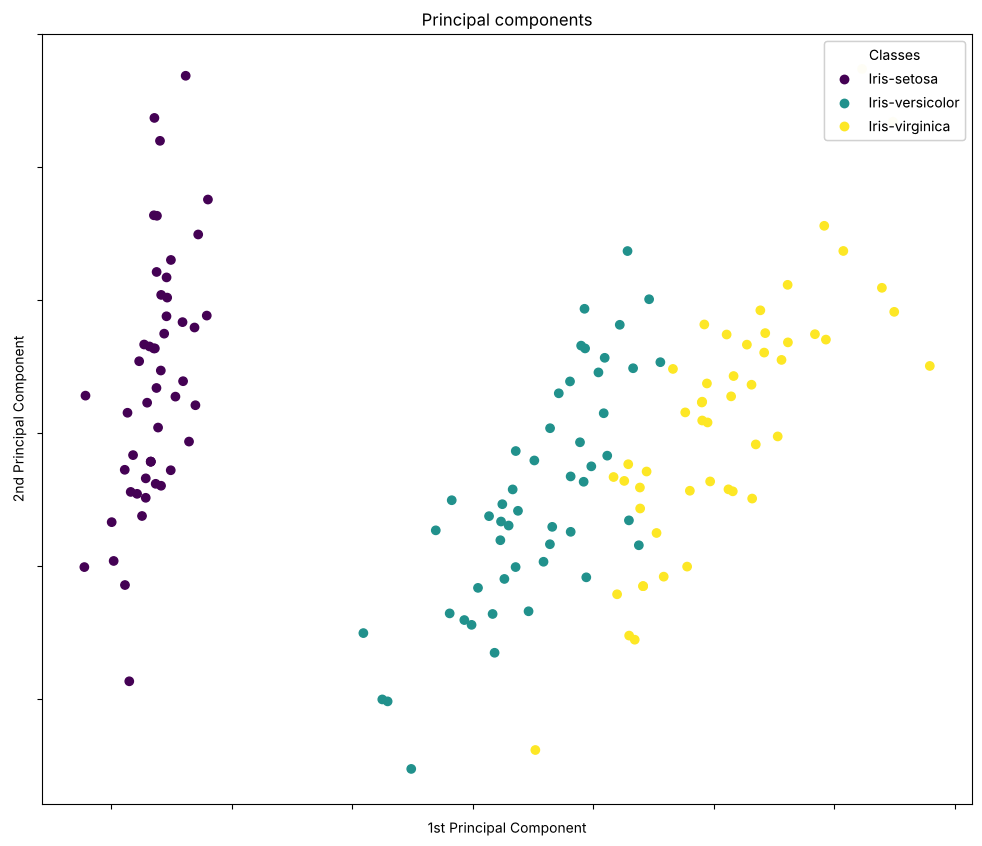

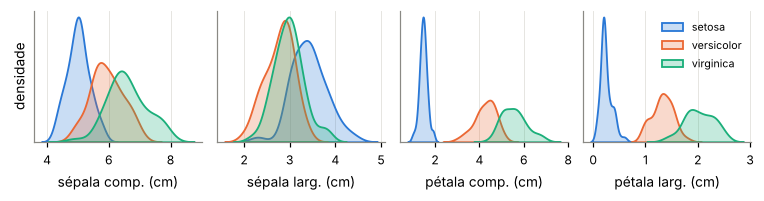

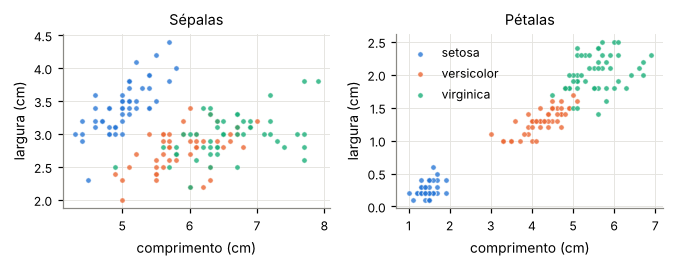

In [52]:
fig = plot_feature_densities(X, y); save_figure(fig, 'distribuicoes'); plt.show()
fig = plot_sepal_petal(X, y); save_figure(fig, 'dispersao'); plt.show()

## PCA: variância explicada e cargas

A seção *PCA* acima projetou os dados **sem padronização**. Aqui medimos quanto da variância cada componente explica e quanto cada medida contribui para ele (cargas), sem e com padronização.

sem padronização: variância explicada [0.9246, 0.053, 0.0172, 0.0052] | 2 PCs: 0.9776 | 3 PCs: 0.9948


,PC1,PC2
sepal length,0.362,0.657
sepal width,-0.082,0.730
petal length,0.857,-0.176
petal width,0.359,-0.075


com padronização: variância explicada [0.7277, 0.2303, 0.0368, 0.0052] | 2 PCs: 0.9580 | 3 PCs: 0.9948


,PC1,PC2
sepal length,0.522,0.372
sepal width,-0.263,0.926
petal length,0.581,0.021
petal width,0.566,0.065


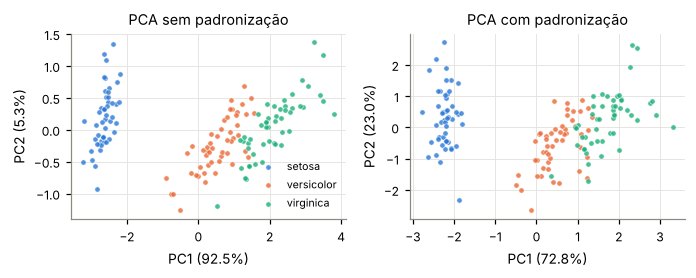

In [53]:
proj, R['pca'] = {}, {}
for nome, std in [('sem padronização', False), ('com padronização', True)]:
    ev, loadings, Z = pca_summary(df, 'target', standardize=std)
    proj[f'PCA {nome}'] = (Z, ev)
    R['pca'][nome] = {'var_explicada': ev.round(4).tolist(), 'cargas_PC1': loadings['PC1'].round(3).to_dict(),
                      'cargas_PC2': loadings['PC2'].round(3).to_dict()}
    print(f"{nome}: variância explicada {ev.round(4).tolist()} | 2 PCs: {ev.iloc[:2].sum():.4f} | 3 PCs: {ev.iloc[:3].sum():.4f}")
    display(loadings[['PC1', 'PC2']].round(3))
fig = plot_pca_projections(proj, y); save_figure(fig, 'pca'); plt.show()

## Variabilidade da divisão treino/teste

O experimento original usa uma divisão aleatória sem semente. Repetimos exatamente o mesmo procedimento (80/20, `StandardScaler` + KNN com *k* = 3) com as sementes 0 a 999, sem e com estratificação. Também conferimos que precisão e sensibilidade *micro* são sempre iguais à acurácia, o que explica os três valores de 0,93 iguais.

precisão micro = sensibilidade micro = acurácia em todas as divisões: True
nao_estratificada : 0.9454 ± 0.0384 | mín 0.800 | máx 1.000 | P(acc ≤ 0,933) = 0.498 | P(acc = 1) = 0.157
estratificada     : 0.9468 ± 0.0387 | mín 0.800 | máx 1.000 | P(acc ≤ 0,933) = 0.490 | P(acc = 1) = 0.182


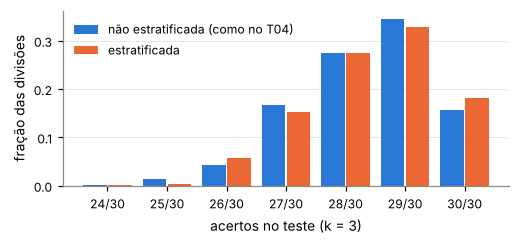

In [54]:
acc_ns, micro_ok = split_variability(df, 'target', n_splits=1000, stratify=False)
acc_st, _ = split_variability(df, 'target', n_splits=1000, stratify=True)
print("precisão micro = sensibilidade micro = acurácia em todas as divisões:", micro_ok)
R['micro_igual_acuracia'] = micro_ok; R['variabilidade'] = {}
for nome, a in [('nao_estratificada', acc_ns), ('estratificada', acc_st)]:
    R['variabilidade'][nome] = {'media': float(a.mean()), 'dp': float(a.std()), 'min': float(a.min()), 'max': float(a.max()),
                                'p_le_933': float(np.mean(a <= 0.9334)), 'p_100': float(np.mean(a == 1))}
    print(f"{nome:18s}: {a.mean():.4f} ± {a.std():.4f} | mín {a.min():.3f} | máx {a.max():.3f} | "
          f"P(acc ≤ 0,933) = {np.mean(a <= 0.9334):.3f} | P(acc = 1) = {np.mean(a == 1):.3f}")
fig = plot_split_variability({'não estratificada (como no T04)': acc_ns, 'estratificada': acc_st})
save_figure(fig, 'variabilidade'); plt.show()

## Divisão estratificada fixa: matriz de confusão e métricas por classe

Daqui em diante usamos uma divisão **estratificada** com semente fixa (`random_state=42`): 120 amostras de treino (40 por classe) e 30 de teste (10 por classe). O teste fica reservado para a avaliação final.

In [55]:
train_s, test_s = split_data(df, 'target', test_size=0.2, stratify=True, random_state=42)
print("treino:", np.bincount(train_s.y), " teste:", np.bincount(test_s.y))
knn3 = train_knn(train_s, n_neighbors=3)
rep3, cm3, acc3 = evaluate_per_class(knn3, test_s, CLASS_NAMES)
print(f"acurácia de teste (k = 3): {acc3:.4f}"); display(rep3.round(3)); print("matriz de confusão (linhas = real):\n", cm3)
R['k3_teste'] = {'acc': acc3, 'cm': cm3.tolist(), 'precisao': rep3['precisão'].round(3).tolist(),
                 'sensibilidade': rep3['sensibilidade'].round(3).tolist(), 'f1': rep3['F1'].round(3).tolist()}

treino: [40 40 40]  teste: [10 10 10]
acurácia de teste (k = 3): 0.9333


,precisão,sensibilidade,F1,amostras
setosa,1.000,1.0,1.000,10
versicolor,0.833,1.0,0.909,10
virginica,1.000,0.8,0.889,10


matriz de confusão (linhas = real):
 [[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]


## Escolha de *k* por validação cruzada

Validação cruzada estratificada de 10 *folds* × 10 repetições **só no treino**, para *k* ímpar de 1 a 59. Valores pares ficam de fora porque, com *k* par, empates de votos são frequentes e o scikit-learn os decide a favor da classe de menor índice. A acurácia no próprio treino (ressubstituição) mostra o sobreajuste: com *k* = 1 ela é sempre 100%.

,k,acc treino,acc CV,dp CV
0,1,1.0000,0.9308,0.0688
1,3,0.9583,0.9558,0.0546
2,5,0.9750,0.9550,0.0558
3,7,0.9750,0.9550,0.0545
4,9,0.9583,0.9433,0.0633
5,11,0.9583,0.9467,0.0629
7,15,0.9667,0.9433,0.0622
10,21,0.9500,0.9417,0.0629
12,25,0.9583,0.9183,0.0764
15,31,0.9000,0.8833,0.0816


melhor k: 3


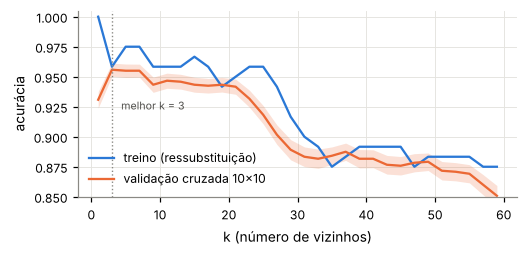

In [56]:
df_k = select_k(train_s, ks=range(1, 60, 2))
k_best = int(df_k.loc[df_k['acc CV'].idxmax(), 'k'])        # empate: o menor k
display(df_k[df_k.k.isin([1, 3, 5, 7, 9, 11, 15, 21, 25, 31, 41, 51, 59])].round(4))
print(f"melhor k: {k_best}")
R['k_cv'] = {'k_best': k_best, 'tabela': df_k.round(4).to_dict('records')}
fig = plot_k_selection(df_k, k_best); save_figure(fig, 'escolha_k'); plt.show()

## Pré-processamento e atributos: KNN com e sem PCA

Mesmo protocolo de validação cruzada no treino. O PCA e a padronização ficam dentro do *pipeline*, então são ajustados apenas nos dados de treino de cada *fold*.

In [57]:
PET, SEP = ['petal length', 'petal width'], ['sepal length', 'sepal width']
def configuracoes(k):
    return {
        'sem padronização':               (FEATURES, lambda: train_knn_pipeline(k, steps=[])),
        'z-score (T04)':                  (FEATURES, lambda: train_knn_pipeline(k)),
        'min-max':                        (FEATURES, lambda: train_knn_pipeline(k, steps=[('scaler', MinMaxScaler())])),
        'PCA 2 comp. (sem padronização)': (FEATURES, lambda: train_knn_pipeline(k, steps=[('pca', PCA(2))])),
        'z-score + PCA 2 comp.':          (FEATURES, lambda: train_knn_pipeline(k, steps=[('scaler', StandardScaler()), ('pca', PCA(2))])),
        'z-score + PCA 3 comp.':          (FEATURES, lambda: train_knn_pipeline(k, steps=[('scaler', StandardScaler()), ('pca', PCA(3))])),
        'z-score, só pétalas':            (PET, lambda: train_knn_pipeline(k)),
        'z-score, só sépalas':            (SEP, lambda: train_knn_pipeline(k)),
        'z-score, pesos por distância':   (FEATURES, lambda: train_knn_pipeline(k, weights='distance')),
        'z-score, distância Manhattan':   (FEATURES, lambda: train_knn_pipeline(k, p=1)),
    }
tab = None
for k in [k_best, k_best + 2]:
    t = compare_configs(train_s, configuracoes(k)).rename(columns={'acc CV': f'k={k} média', 'dp CV': f'k={k} dp'})
    tab = t if tab is None else tab.merge(t, on='configuração')
display(tab.round(4))
melhor = tab.loc[tab[f'k={k_best} média'].idxmax(), 'configuração']
print("melhor configuração:", melhor)
R['variantes'] = tab.round(4).to_dict('records'); R['melhor_variante'] = melhor

,configuração,k=3 média,k=3 dp,k=5 média,k=5 dp
0,sem padronização,0.9533,0.0569,0.9700,0.0449
1,z-score (T04),0.9558,0.0546,0.9550,0.0558
2,min-max,0.9658,0.0458,0.9658,0.0473
3,PCA 2 comp. (sem padronização),0.9717,0.0412,0.9692,0.0451
4,z-score + PCA 2 comp.,0.8950,0.0822,0.9258,0.0735
5,z-score + PCA 3 comp.,0.9633,0.0544,0.9567,0.0559
6,"z-score, só pétalas",0.9492,0.0539,0.9617,0.0533
7,"z-score, só sépalas",0.7575,0.1173,0.7783,0.0988
8,"z-score, pesos por distância",0.9558,0.0546,0.9542,0.0557
9,"z-score, distância Manhattan",0.9425,0.0620,0.9542,0.0582


melhor configuração: PCA 2 comp. (sem padronização)


## Avaliação final e análise dos erros

A configuração do relatório original (*z-score*, *k* = 3) é comparada com a melhor configuração da validação cruzada. A comparação usa o teste reservado e a validação cruzada 10×10 nas 150 amostras, que também conta quantas vezes cada flor foi classificada errado.

== T04 (z-score, k=3) [z-score (T04)]  teste: 0.9333   CV 10x10 (150 amostras): 0.9467 ± 0.0516


,precisão,sensibilidade,F1,amostras
setosa,1.000,1.0,1.000,10
versicolor,0.833,1.0,0.909,10
virginica,1.000,0.8,0.889,10


matriz de confusão agregada da CV:
 [[490  10   0]
 [  0 469  31]
 [  0  39 461]]


== final [PCA 2 comp. (sem padronização)]  teste: 0.9667   CV 10x10 (150 amostras): 0.9733 ± 0.0377


,precisão,sensibilidade,F1,amostras
setosa,1.000,1.0,1.000,10
versicolor,0.909,1.0,0.952,10
virginica,1.000,0.9,0.947,10


matriz de confusão agregada da CV:
 [[500   0   0]
 [  0 477  23]
 [  0  17 483]]


,índice,classe,erros final (de 10),erros T04 (de 10),sepal length,sepal width,petal length,petal width
3,72,versicolor,10,10,6.3,2.5,4.9,1.5
6,106,virginica,10,10,4.9,2.5,4.5,1.7
5,83,versicolor,10,10,6.0,2.7,5.1,1.6
12,149,virginica,4,0,5.9,3.0,5.1,1.8
2,70,versicolor,2,9,5.9,3.2,4.8,1.8
11,138,virginica,2,1,6.0,3.0,4.8,1.8
8,126,virginica,1,0,6.2,2.8,4.8,1.8
4,77,versicolor,1,1,6.7,3.0,5.0,1.7
0,41,setosa,0,10,4.5,2.3,1.3,0.3
1,68,versicolor,0,1,6.2,2.2,4.5,1.5


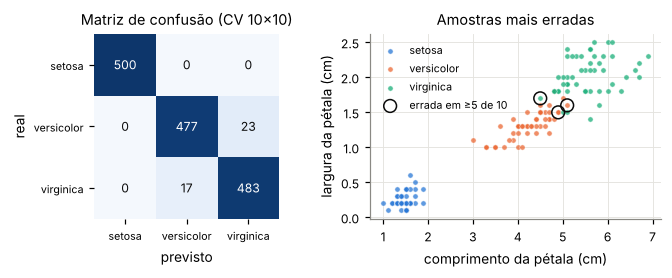

In [58]:
R['final'] = {'config': melhor, 'k': k_best}
erros = {}
for rotulo, nome in [('T04 (z-score, k=3)', 'z-score (T04)'), ('final', melhor)]:
    feats, factory = configuracoes(k_best)[nome]
    modelo = factory().fit(train_s.X[feats], train_s.y)
    rep, cm_te, acc_te = evaluate_per_class(modelo, test_s, CLASS_NAMES, features=feats)
    accs, cm_cv, err = cross_validation_errors(X[feats], y, factory)
    erros[rotulo] = (cm_cv, err)
    R['final'][rotulo] = {'nome': nome, 'teste_acc': acc_te, 'teste_cm': cm_te.tolist(),
                          'teste_precisao': rep['precisão'].round(3).tolist(), 'teste_sens': rep['sensibilidade'].round(3).tolist(),
                          'teste_f1': rep['F1'].round(3).tolist(), 'cv_media': float(accs.mean()), 'cv_dp': float(accs.std()),
                          'cv_cm': cm_cv.tolist(), 'erros': {int(i): int(err[i]) for i in np.where(err > 0)[0]}}
    print(f"== {rotulo} [{nome}]  teste: {acc_te:.4f}   CV 10x10 (150 amostras): {accs.mean():.4f} ± {accs.std():.4f}")
    display(rep.round(3)); print("matriz de confusão agregada da CV:\n", cm_cv)
ef, eo = erros['final'][1], erros['T04 (z-score, k=3)'][1]
idx = np.where((ef > 0) | (eo > 0))[0]
display(pd.DataFrame({'índice': idx, 'classe': [CLASS_NAMES[y[i]] for i in idx], 'erros final (de 10)': ef[idx],
                      'erros T04 (de 10)': eo[idx]}).join(X.iloc[idx].reset_index(drop=True)).sort_values('erros final (de 10)', ascending=False))
fig = plot_confusion_and_errors(erros['final'][0], X, y, ef, min_errors=5); save_figure(fig, 'erros'); plt.show()

## Fronteiras de decisão no plano do PCA

KNN treinado nos dois primeiros componentes do PCA sem padronização (como na seção *PCA*), ajustado só no treino. Com *k* = 1 a fronteira contorna cada ponto de treino (sobreajuste). Com o *k* escolhido ela fica mais regular. Com *k* = 59, metade do treino, ela perde detalhes (subajuste).

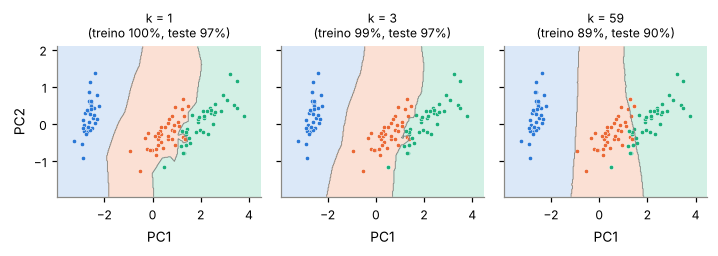

,k,acc treino,acc teste
0,1,1.000000,0.966667
1,3,0.991667,0.966667
2,59,0.891667,0.900000


In [59]:
pca2 = PCA(2).fit(train_s.X)
fig, fr = plot_decision_boundaries(pca2.transform(train_s.X), train_s.y.to_numpy(), pca2.transform(test_s.X), test_s.y.to_numpy(),
                                   ks=[1, k_best, 59], classifier_factory=lambda k: KNeighborsClassifier(k))
save_figure(fig, 'fronteiras'); plt.show()
display(pd.DataFrame(fr)); R['fronteiras'] = fr

In [60]:
def _conv(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
json.dump(R, open('resultados.json', 'w'), indent=1, default=_conv, ensure_ascii=False)
print('resultados.json salvo')

resultados.json salvo


## Conclusões da análise complementar

* A *setosa* é separada por qualquer medida da pétala. Todos os erros do KNN estão entre *versicolor* e *virginica*, concentrados em poucas flores atípicas.
* Sem padronização, o PC1 explica cerca de 92% da variância e é dominado pelo comprimento da pétala. Por isso o KNN nos dois primeiros componentes **sem** padronização foi a melhor configuração. Com padronização, o PC2 vira quase só a largura da sépala e a classificação piora.
* O *k* = 3 do relatório original estava entre os melhores. O resultado de 0,93 era uma única divisão, de uma distribuição que vai de 0,80 a 1,00. A validação cruzada dá uma estimativa mais estável.